# Notebook 2B - Phase 2 + Phase 3, **Part B = Session 2**

Folds trained in this notebook: **Ses02F** and **Ses02M** (leave-one-speaker-out; the held-out speaker is never used for training).
Uses `phase1_Ses02F.pt` and `phase1_Ses02M.pt`, builds the full model (Spatial CNN + Wav2Vec2 + Fusion + Classifier) and runs the soft-label correction (Phase 2 + 3) on each fold's training speakers. The **final-epoch** model is saved.

**Run:** Save Version -> **Save & Run All (Commit)**. Expected time: about 3 h on T4 x2 (10 epochs per fold). Run the 5 parts **one at a time**.

**Inputs to attach:** (1) all-sessions preprocessed dataset, (2) Wav2Vec model dataset, (3) Phase 1 output *first 5 fold*, (4) Phase 1 output *last 5 fold*. If this notebook stops early, attach **its own previous version's output** and run again - it resumes from the last checkpoint.

**Outputs** (`/kaggle/working/loso23/`): `phase3_Ses02F.pt`, `phase3_Ses02M.pt`, `result_<fold>.json`.

After Parts A-E are all finished, run **Notebook 3 (final evaluation)**.

## 1. Install dependencies

In [1]:
# On Kaggle's GPU T4x2 image, torch/torchaudio are already installed and matched
# to the CUDA driver -- reinstalling them with pip can silently swap in a CPU-only
# or mismatched build. Only install/upgrade what's actually missing.
!pip install -q -U transformers
!pip install -q ipywidgets


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 549.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 441.9 kB/s eta 0:00:00


In [2]:
import torch
import transformers
import torchaudio

print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)
print("Is CUDA (GPU) available?", torch.cuda.is_available())


PyTorch Version: 2.11.0+cu128
Transformers Version: 5.19.0
Is CUDA (GPU) available? True


## 2. Kaggle paths, device, part-control helpers

In [3]:
import os, glob, json, time, re, gc, math, torch
import numpy as np

# ---- Device & GPU info (Kaggle "GPU T4 x2" gives you 2 GPUs) ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_gpus = torch.cuda.device_count()
print("Using device:", device, "| GPUs visible:", n_gpus)
for i in range(n_gpus): print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

def maybe_parallel(model):
    """Wrap in DataParallel so forward() uses both T4s. Always optimise / save the ORIGINAL (unwrapped) model."""
    return torch.nn.DataParallel(model) if n_gpus > 1 else model

OUTPUT_DIR = "/kaggle/working"; os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------- PART CONTROL (so a long run can be split over several Kaggle sessions) ----------------
SESSION_BUDGET_HOURS = 10.5     # after this many hours the run SAVES its state and stops cleanly (Kaggle kills a session at 12 h)
T_START = time.time()
class StopPart(Exception): pass
def out_of_time(): return (time.time() - T_START) / 3600.0 > SESSION_BUDGET_HOURS

def find_file(name):
    """Look for a file by NAME first in this notebook's /kaggle/working, then in EVERY attached input
    (e.g. the saved output of an earlier part). Returns the newest match or None."""
    hits = glob.glob(os.path.join(OUTPUT_DIR, "**", name), recursive=True)
    for root, _, files in os.walk("/kaggle/input"):
        if name in files: hits.append(os.path.join(root, name))
    return max(hits, key=os.path.getmtime) if hits else None

# ---------------- the preprocessed ALL-SESSIONS file ----------------
PT_PATH_OVERRIDE = "/kaggle/input/datasets/bdivyabalamurugan/preprocess-session-1-to-5/processed/processed_first_all.pt"         # set e.g. "/kaggle/input/datasets/<user>/<dataset>/processed/processed_all.pt" if the auto-pick below is wrong
def _pick_pt():
    c = [p for p in glob.glob("/kaggle/input/**/*.pt", recursive=True) if "processed" in os.path.basename(p).lower()]
    for p in sorted(c): print(f"   candidate: {p}  ({os.path.getsize(p)/1e9:.2f} GB)")
    return max(c, key=os.path.getsize) if c else None      # the all-sessions file is the biggest one
PT_PATH = PT_PATH_OVERRIDE or _pick_pt()
print("PT_PATH ->", PT_PATH, "| exists:", bool(PT_PATH) and os.path.exists(PT_PATH))
if not PT_PATH or not os.path.exists(PT_PATH):
    raise FileNotFoundError("No preprocessed 'processed*.pt' found under /kaggle/input. Attach your all-sessions dataset ('+ Add Input') or set PT_PATH_OVERRIDE.")

# ---------------- Wav2Vec2 weights folder ----------------
WAV2VEC_DEFAULT = "/kaggle/input/datasets/bdivyalakshmi/wav2vec-model/wav2vec2_stored"
def _find_wav2vec_dir():
    if os.path.isdir(WAV2VEC_DEFAULT): return WAV2VEC_DEFAULT
    for root, dirs, files in os.walk("/kaggle/input"):
        if os.path.basename(root) == "wav2vec2_stored" and "config.json" in files: return root
    for root, dirs, files in os.walk("/kaggle/input"):
        if "config.json" in files and "wav2vec" in root.lower(): return root
    return WAV2VEC_DEFAULT
WAV2VEC_DIR = _find_wav2vec_dir()
print("Wav2Vec2 weights ->", WAV2VEC_DIR, "| exists:", os.path.isdir(WAV2VEC_DIR))
print("OUTPUT_DIR ->", OUTPUT_DIR)


Using device: cuda | GPUs visible: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4
PT_PATH -> /kaggle/input/datasets/bdivyabalamurugan/preprocess-session-1-to-5/processed/processed_first_all.pt | exists: True
Wav2Vec2 weights -> /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored | exists: True
OUTPUT_DIR -> /kaggle/working


## 3. Spatial Module (CNN) -- Section IV-B

In [4]:
"""
================================================================================
Spatial Module (CNN) -- Section IV-B / Fig. 2 & 3 of the paper
================================================================================
INPUT
-----
X_in ∈ R^{1 x f x M}   where:
    1 = channel dimension (like a single-channel/grayscale image)
    f = number of time frames -- VARIES between utterances (e.g. 150, 334, 701
        in your own preprocessed data, depending on clip length)
    M = 40, number of Mel filterbank channels -- ALWAYS fixed at 40

THE KEY QUESTION YOU ASKED: "what is the input node count, since f and M
aren't equal / f varies between samples?"
-----------------------------------------------------------------------------
There is NO fixed "input node count" here, because this is a fully
convolutional network, not a dense/MLP network:
  - Conv2D layers slide the same small kernel across the input regardless of
    its height/width -- a 3x3 kernel works identically whether the input
    is 150 frames tall or 701 frames tall. Conv layers don't care about f.
  - The only place f's SIZE would matter is if we flattened the feature map
    into a fixed-length vector for a Dense/Linear layer. This architecture
    deliberately avoids that: it ends with GLOBAL AVERAGE POOLING (GAP),
    which averages over whatever f and M happen to be, always producing a
    fixed (96,) vector no matter the input's frame count.
  - So: f can be 150 for one sample and 701 for another in the SAME batch
    (after collate_fn's padding, they're equal within a batch, but they
    still vary ACROSS batches/samples) -- the network handles this natively.

ARCHITECTURE (matches Fig. 3 + Eq. 21-23 exactly)
--------------------------------------------------
1) Three PARALLEL convolutional branches on X_in, each producing 8 channels:
     Conv1a: kernel (11, 1)  -- "temporal" branch (tall, thin kernel along f)
     Conv1b: kernel (1, 9)   -- "spectral" branch (wide, short kernel along M)
     Conv1c: kernel (5, 5)   -- "joint" branch (square kernel, both axes)
   Each branch is followed by BatchNorm + ReLU, then a 2x2 downsample
   (stride-2), per Fig. 3's "Down sample" boxes.

2) Concatenate all three branches channel-wise:
     Xc = concat(branch_a, branch_b, branch_c) -> 8+8+8 = 24 channels
     Xc ∈ R^{24 x f/2 x M/2}

3) Five consecutive 3x3 conv layers deepen the representation:
     channels grow: 24 -> 32 -> 48 -> 64 -> 80 -> 96
   The FIRST FOUR of these five layers each downsample by 2 (stride-2);
   the FIFTH does NOT downsample (paper: "no downsampling applied after the
   final convolution, to preserve critical information").
     4 downsamples of factor 2 -> f/2 shrinks by another 16x -> f/32 total
     Xd ∈ R^{96 x f/32 x M/32}

4) Global Average Pooling collapses (f/32, M/32) entirely:
     Xs = GAP(Xd) ∈ R^{96}     <- ALWAYS 96-dim, regardless of original f

Xs is the fixed-size spatial embedding fed into the Multi-Level Fusion Module
(Sec. IV-D) alongside the temporal embedding Ft from Wav2Vec 2.0.
================================================================================
"""

import torch
import torch.nn as nn


class ParallelConvBranch(nn.Module):
    """One of the three parallel branches: conv -> BN -> ReLU -> 2x2 downsample."""

    def __init__(self, in_channels: int, out_channels: int, kernel_size):
        super().__init__()
        # 'same' padding so the branch doesn't shrink the map before downsampling
        if isinstance(kernel_size, int):
            kernel_size = (kernel_size, kernel_size)
        padding = (kernel_size[0] // 2, kernel_size[1] // 2)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = nn.AvgPool2d(kernel_size=2, stride=2, ceil_mode=True)

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        x = self.downsample(x)
        return x


class DeepConvBlock(nn.Module):
    """One of the five 3x3 conv layers in the deepening stack (Xc -> Xd)."""

    def __init__(self, in_channels: int, out_channels: int, downsample: bool):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = nn.AvgPool2d(kernel_size=2, stride=2, ceil_mode=True) if downsample else None

    def forward(self, x):
        x = self.relu(self.bn(self.conv(x)))
        if self.downsample is not None:
            x = self.downsample(x)
        return x


class SpatialCNN(nn.Module):
    """
    Full Spatial Module, Section IV-B. Input: (B, 1, f, 40). Output: (B, 96).
    Works for ANY f (any number of time frames) -- that's the whole point of
    ending in Global Average Pooling instead of a Linear/Dense layer.
    """

    def __init__(self, n_mels: int = 40, branch_channels: int = 8, final_dim: int = 96):
        super().__init__()
        self.branch_a = ParallelConvBranch(1, branch_channels, kernel_size=(11, 1))  # temporal
        self.branch_b = ParallelConvBranch(1, branch_channels, kernel_size=(1, 9))   # spectral
        self.branch_c = ParallelConvBranch(1, branch_channels, kernel_size=(5, 5))   # joint

        concat_channels = branch_channels * 3  # 8+8+8 = 24

        # 5 deepening conv layers: channels 24->32->48->64->80->96
        # first 4 downsample, last one does not (paper's explicit design choice)
        channel_steps = [concat_channels, 32, 48, 64, 80, final_dim]
        blocks = []
        for i in range(5):
            downsample = (i < 4)  # only the first 4 of 5 layers downsample
            blocks.append(DeepConvBlock(channel_steps[i], channel_steps[i + 1], downsample))
        self.deep_blocks = nn.Sequential(*blocks)

        self.gap = nn.AdaptiveAvgPool2d(output_size=1)  # -> (B, 96, 1, 1) regardless of input H,W

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, 1, f, 40)
        a = self.branch_a(x)
        b = self.branch_b(x)
        c = self.branch_c(x)
        Xc = torch.cat([a, b, c], dim=1)      # (B, 24, f/2, 40/2)   -- Eq. 21

        Xd = self.deep_blocks(Xc)              # (B, 96, f/32, 40/32) -- Eq. 22

        Xs = self.gap(Xd)                       # (B, 96, 1, 1)        -- Eq. 23
        Xs = Xs.flatten(1)                      # (B, 96)  <- FIXED SIZE, any f in, same size out
        return Xs

## 4. Temporal Module (Wav2Vec 2.0) -- Section IV-C

In [5]:
"""
================================================================================
Temporal Module (Wav2Vec 2.0) -- Section IV-C / Fig. 4 of the paper
================================================================================
INPUT
-----
x_i : raw 16kHz waveform, shape (T,) -- T = number of RAW AUDIO SAMPLES, which
also varies between utterances (e.g. your own samples: 24000, 53360, 112000
samples for different clip lengths). No fixed input size here either, for
the same underlying reason as the CNN branch: this ends in a POOLING step
that collapses variable length down to a fixed-size vector.

ARCHITECTURE (matches Eq. 24-28 + Fig. 4)
------------------------------------------
Wav2Vec 2.0 itself already contains:
  a) A stack of 1D convolutions (its own internal "feature encoder") that
     turns the raw waveform into a sequence of frames:
         G ∈ R^{T' x d1}   (T' = number of frames, varies with input length;
                             d1 = 512 for wav2vec2-base)
  b) A linear projection into the transformer's hidden size:
         G' = Linear(G) ∈ R^{T' x d2}     (d2 = 768 for wav2vec2-base)   -- Eq. 24
  c) An optional MASKING step during fine-tuning (randomly masks some frames,
     a regularization trick borrowed from masked-language-modeling) -- Eq. 25.
     This is a BUILT-IN feature of HuggingFace's Wav2Vec2Model, controlled by
     config.mask_time_prob / config.mask_time_length, and (per Table I in the
     paper) uses the HuggingFace wav2vec2-base-960h model's DEFAULT masking
     config -- so we don't hand-implement masking, we just use the pretrained
     model as-is with masking enabled during training.
  d) The Transformer encoder stack (also built into Wav2Vec2Model):
         F2 = Transformer(F1) ∈ R^{T' x d2}                              -- Eq. 26

WHAT WE ADD ON TOP (this is the paper's own custom aggregation, Eq. 27-28):
Wav2Vec 2.0's native output F2 is still PER-FRAME (T' x d2) -- one vector
per time step, and T' varies between utterances. To get one FIXED-SIZE
vector per utterance (needed for fusion with the CNN's Xs), the paper adds:
  e) A learned linear layer that turns each frame's d2-dim vector into a
     single attention-style weight:
         F2' = Linear(F2) ∈ R^{1 x T'}                                    -- Eq. 27
     (we apply softmax over T' here, turning F2' into proper attention
      weights that sum to 1 -- a standard, reasonable choice consistent
      with the paper's "weighted aggregation" description, though the paper
      doesn't spell out softmax explicitly)
  f) Multiply those weights by F2 and sum over time (matrix multiplication):
         Ft = F2' ⊗ F2 ∈ R^{1 x d2}                                       -- Eq. 28
     This is a weighted average over ALL T' frames -- so REGARDLESS of how
     many frames T' there were, Ft always comes out as a fixed d2-dim vector.

Ft is the fixed-size temporal embedding fed into the Multi-Level Fusion
Module (Sec. IV-D) alongside the spatial embedding Xs from the CNN.

DEPENDENCY NOTE
---------------
Requires the `transformers` library (HuggingFace):
    pip install transformers
Uses the pretrained "facebook/wav2vec2-base-960h" checkpoint, matching the
paper's Table I description of the masking configuration.

*** NEW: `set_unfrozen_layers()` (added for gradual unfreezing) ***
Training was learning slowly because 10/12 transformer layers were frozen
for the ENTIRE run (a safe-but-slow fix for earlier NaN instability). This
method lets the training loop progressively open up more layers as training
stabilizes, instead of being stuck at 10/12 frozen forever. See the Phase 1
and Phase 3 training-loop cells below for how it's used.
================================================================================
"""

import torch
import torch.nn as nn
from transformers import Wav2Vec2Model, Wav2Vec2Config


class TemporalWav2Vec2(nn.Module):
    """
    Full Temporal Module, Section IV-C. Input: (B, T) raw 16kHz waveform.
    Output: (B, 768) -- ALWAYS 768-dim (wav2vec2-base's hidden size),
    regardless of T (the number of raw audio samples in the input).
    """

    def __init__(self, pretrained_name: str = None,
                 freeze_feature_encoder: bool = True,
                 freeze_transformer_layers: int = 10):
        """
        freeze_transformer_layers: how many of wav2vec2-base's 12 transformer
        encoder layers to FREEZE (starting from layer 0, the earliest/most
        general ones), leaving the remaining top layers + our pooling head
        trainable. This is the standard, well-documented fix for wav2vec2-base
        fine-tuning instability (NaN loss/gradients): fully unfreezing all 12
        transformer layers at once, on top of a randomly-initialized head,
        lets large early gradients from the head propagate all the way back
        through the pretrained weights and destabilize them. Only letting the
        last ~2 layers adapt keeps the bulk of the pretrained representation
        intact while still allowing task-specific adaptation near the output.
        Set to 0 to fine-tune all 12 layers (the old, unstable behavior).
        """
        super().__init__()
        pretrained_name = pretrained_name or WAV2VEC_DIR       # resolved in the paths cell
        self.wav2vec2 = Wav2Vec2Model.from_pretrained(pretrained_name)
        hidden_size = self.wav2vec2.config.hidden_size  # 768 for wav2vec2-base

        if freeze_feature_encoder:
            # Common practice: freeze the low-level CNN feature extractor
            # (already well pretrained on huge unlabeled speech corpora),
            # and only fine-tune the transformer layers + our new pooling head.
            self.wav2vec2.feature_extractor._freeze_parameters()

        self.set_unfrozen_layers(freeze_transformer_layers)

        # *** FIX: freeze masked_spec_embed ***
        # This is Wav2Vec2's single learned "mask token" vector (substituted
        # in for masked time-steps during spec-augment-style training). It's
        # a standalone top-level Parameter, NOT part of encoder.layers, so the
        # freezing loop above never touched it -- it stayed fully trainable
        # and, over 8 epochs, its magnitude ran away to ~1.89e38 (right at
        # float32's ceiling of ~3.4e38, one step from overflowing to inf).
        # A near-infinite value substituted into the hidden-state sequence
        # for every masked frame is very likely what's been driving the
        # batch-wide NaNs all along. There's no real need to fine-tune this
        # token for our task, so we freeze it at its pretrained value.
        if hasattr(self.wav2vec2, "masked_spec_embed"):
            mse = self.wav2vec2.masked_spec_embed
            # *** THE ACTUAL FIX ***
            # Freezing this parameter (below) only stops it from getting WORSE
            # during fine-tuning -- it does nothing if the value was already
            # broken the moment the checkpoint loaded. And that's exactly
            # what's happening: HuggingFace initializes masked_spec_embed with
            # Uniform(0, 1) -- a healthy value should never be anywhere near
            # 1e38. Finding it already at ~1.89e38 BEFORE any training step
            # means this specific locally-stored checkpoint file
            # (wav2vec2_stored) has this one parameter corrupted at the
            # source, unrelated to anything in this notebook. Freezing a
            # broken value just keeps it broken forever, which is why the
            # skip-count kept climbing at the same rate even after we froze
            # it last time. The real fix: detect this and RESET it to a sane
            # value (matching HF's own default init) before freezing it.
            if not torch.isfinite(mse).all() or mse.abs().max().item() > 10.0:
                print(f"[TemporalWav2Vec2] WARNING: masked_spec_embed loaded "
                      f"from the checkpoint is already corrupted "
                      f"(max abs={mse.abs().max().item():.3e}), BEFORE any "
                      f"fine-tuning -- this is a broken checkpoint file, not "
                      f"a training issue. Re-initializing it to HF's own "
                      f"default Uniform(0, 1) range instead of using the "
                      f"broken saved value.")
                with torch.no_grad():
                    mse.uniform_(0.0, 1.0)
            mse.requires_grad = False
            print("[TemporalWav2Vec2] Froze masked_spec_embed (mask-token "
                  "vector) to prevent it from diverging during fine-tuning.")

        # Eq. 27: per-frame -> single attention-style scalar weight
        self.attn_proj = nn.Linear(hidden_size, 1)

    def set_unfrozen_layers(self, freeze_transformer_layers: int) -> int:
        """*** NEW: supports GRADUAL UNFREEZING ***
        Freezes the first `freeze_transformer_layers` encoder layers and
        unfreezes the rest. Called once from __init__ (the original static
        behavior), and can also be called again LATER, mid-training, by the
        training loop to progressively open up more of the backbone once
        the loss has stabilized -- instead of leaving 10/12 layers frozen
        for the entire run, which is safe but needlessly slow.
        Returns the actual number of frozen layers (clamped to [0, n_layers]).
        """
        n_layers = len(self.wav2vec2.encoder.layers)   # 12 for wav2vec2-base
        n_freeze = max(0, min(freeze_transformer_layers, n_layers))
        for i, layer in enumerate(self.wav2vec2.encoder.layers):
            requires_grad = i >= n_freeze
            for p in layer.parameters():
                p.requires_grad = requires_grad
        print(f"[TemporalWav2Vec2] Froze transformer layers 0-{n_freeze-1} "
              f"of {n_layers}; layers {n_freeze}-{n_layers-1} + pooling head "
              f"remain trainable.")
        return n_freeze

    @staticmethod
    def _normalize_waveform(waveform: torch.Tensor, attention_mask: torch.Tensor = None,
                             eps: float = 1e-7) -> torch.Tensor:
        """*** THE REAL, COMPLETE FIX FOR THE NaN BUG ***
        facebook/wav2vec2-base-960h expects ZERO-MEAN, UNIT-VARIANCE normalized
        audio. The FIRST fix (plain mean()/std() over the whole array) was
        INCOMPLETE: when a batch mixes clips of different real lengths, shorter
        clips get zero-padded to match the longest one in the batch -- e.g. a
        1.5s clip (24000 samples) padded to match a 7s clip (112000 samples)
        has 88000 fake zero samples (78% of its length!). Computing mean/std
        over THAT ENTIRE padded array lets the huge zero-block distort the
        statistics -- std becomes artificially tiny, so dividing by it blows
        the real audio values up to extreme magnitudes -> NaN inside
        Wav2Vec2's internal layers. THIS is what was still causing
        "RuntimeError: NaN/Inf detected..." during Phase 1 training.

        FIX: when an attention_mask is given (1=real audio, 0=padding), compute
        mean/std using ONLY the real (non-padded) positions per sample, so
        padding never distorts the statistics. Falls back to plain mean/std
        when no mask is given (single, un-padded samples -- mathematically
        identical to masked in that case anyway)."""
        # MIN_STD floors the denominator so near-silent/very-low-energy clips don't get
        # divided by a tiny std and amplified into an unrealistic dynamic range that
        # blows up inside Wav2Vec2's pretrained conv stack (the real cause of the
        # "NaN/Inf detected" error even after the padding-aware fix below). The final
        # clamp is a second, independent safety net on the output magnitude itself.
        MIN_STD = 1e-3
        CLAMP_RANGE = 10.0

        # *** ADDITIONAL FIX: sanitize the RAW waveform itself before computing any
        # statistics. The MIN_STD floor + output clamp above only protect against a
        # tiny-but-finite std (e.g. near-silent clips). They do NOT protect against
        # NaN/Inf values that are already present in the input tensor (e.g. from a
        # corrupted source audio file, a bad resample, or a division-by-zero further
        # upstream in preprocessing). If even one NaN/Inf sneaks into `waveform`,
        # mean()/std() over that sample become NaN too, and MIN_STD.clamp() cannot
        # fix a NaN (clamp does not touch NaN values) -- so the NaN silently survives
        # into Wav2Vec2 and triggers the "NaN/Inf detected" crash regardless of the
        # floor/clamp below. Replacing NaN/Inf with 0 here removes the problem at its
        # source, before any statistic is computed from it.
        if not torch.isfinite(waveform).all():
            waveform = torch.nan_to_num(waveform, nan=0.0, posinf=0.0, neginf=0.0)

        if attention_mask is None:
            mean = waveform.mean(dim=-1, keepdim=True)
            std = waveform.std(dim=-1, keepdim=True).clamp(min=MIN_STD)
            normalized = (waveform - mean) / std
            return normalized.clamp(-CLAMP_RANGE, CLAMP_RANGE)

        mask = attention_mask.to(waveform.dtype)                      # (B, T)
        lengths = mask.sum(dim=-1, keepdim=True).clamp(min=1.0)         # (B, 1) real length per sample
        mean = (waveform * mask).sum(dim=-1, keepdim=True) / lengths      # masked mean
        var = ((waveform - mean) ** 2 * mask).sum(dim=-1, keepdim=True) / lengths
        std = torch.sqrt(var.clamp(min=0.0)).clamp(min=MIN_STD)
        normalized = (waveform - mean) / std
        normalized = normalized.clamp(-CLAMP_RANGE, CLAMP_RANGE)
        return normalized * mask   # keep padded positions at exactly 0 after normalizing

    def forward(self, waveform: torch.Tensor,
                attention_mask: torch.Tensor = None) -> torch.Tensor:
        # waveform: (B, T) raw 16kHz audio -> mask-aware normalize BEFORE Wav2Vec2 sees it
        waveform = self._normalize_waveform(waveform, attention_mask)

        outputs = self.wav2vec2(waveform, attention_mask=attention_mask)
        F2 = outputs.last_hidden_state          # (B, T', 768) -- Eq. 26, T' varies with T

        # *** SELF-HEALING FIX (replaces the old hard-crash check) ***
        # We already confirmed (via the diagnostic+filter cell) that the RAW
        # waveforms going in are all finite -- no NaN/Inf, no near-silent clips.
        # So a NaN appearing HERE, in Wav2Vec2's own output, is NOT a bad-data
        # problem -- it's numerical instability inside wav2vec2-base's transformer
        # layers while fine-tuning (a well-known issue with this checkpoint, since
        # it uses post-norm rather than the more stable pre-norm variant used in
        # wav2vec2-large-robust/xlsr). We can't reliably prevent every occurrence
        # of this with a normalization tweak alone, so instead of crashing the
        # whole training run over ONE bad sample in a batch, we:
        #   1. find exactly which sample(s) in this batch went non-finite,
        #   2. zero out just those rows (so they contribute ~nothing and don't
        #      poison the rest of the batch via the pooled attention step below),
        #   3. print a warning so you can see how often / which ones this hits.
        # Training simply continues instead of dying.
        sample_finite = torch.isfinite(F2).flatten(1).all(dim=1)   # (B,) bool
        if not sample_finite.all():
            bad_idx = (~sample_finite).nonzero(as_tuple=True)[0].tolist()
            print(f"[TemporalWav2Vec2] WARNING: non-finite output for local batch "
                  f"indices {bad_idx} (of {F2.shape[0]}) -- zeroing these rows and "
                  f"continuing. If this keeps happening on the SAME utt_id, that "
                  f"clip should be excluded from training; if it's scattered/random, "
                  f"it's fine-tuning instability -- consider lowering the Phase 1 "
                  f"learning rate.")
            F2 = F2.clone()
            F2[~sample_finite] = 0.0

        # Eq. 27: per-frame scalar -> softmax over time -> attention weights
        attn_logits = self.attn_proj(F2)         # (B, T', 1)
        attn_logits = attn_logits.squeeze(-1)    # (B, T')
        if attention_mask is not None:
            # Wav2Vec2 downsamples the mask internally; use its helper to
            # get the mask at the RIGHT resolution for F2 before softmax,
            # so padded frames get (effectively) zero weight.
            feat_mask = self.wav2vec2._get_feature_vector_attention_mask(
                F2.shape[1], attention_mask
            )
            # *** THE ACTUAL ROOT CAUSE OF THE RECURRING NaN GRADIENTS ***
            # If ANY sample in the batch has zero valid (unpadded) frames at
            # this downsampled resolution, masking its entire row to literal
            # -inf makes softmax compute (-inf) - max(-inf) = NaN for every
            # entry in that row (an indeterminate inf-minus-inf, NOT 0). That
            # one NaN row then poisons attn_proj's gradient for the WHOLE
            # BATCH, since attn_proj is one shared Linear layer -- which is
            # exactly why lowering the LR / freezing more transformer layers
            # never fixed this: the instability was never in wav2vec2's own
            # weights, it was here. Using a large FINITE negative sentinel
            # instead of -inf avoids the NaN entirely: softmax subtracts the
            # row max (which is also -1e9 in a fully-masked row), giving 0
            # for every entry -> a harmless uniform distribution instead of
            # NaN. For normal rows (at least one real frame), a padded
            # frame's weight is still ~0 after softmax, same as before.
            attn_logits = attn_logits.masked_fill(feat_mask == 0, -1e9)
            n_fully_masked = (feat_mask.sum(dim=1) == 0).sum().item()
            if n_fully_masked > 0:
                print(f"[TemporalWav2Vec2] NOTE: {n_fully_masked} sample(s) in "
                      f"this batch had ZERO valid frames after downsampling -- "
                      f"falling back to uniform attention for them. This usually "
                      f"means a clip's real (unpadded) length is too short even "
                      f"after zero-padding; worth checking your preprocessing's "
                      f"minimum-length floor if this prints often.")
        attn_weights = torch.softmax(attn_logits, dim=-1)   # (B, T'), sums to 1

        # Eq. 28: Ft = F2' ⊗ F2  (weighted sum over time -> fixed-size vector)
        Ft = torch.bmm(attn_weights.unsqueeze(1), F2)   # (B, 1, 768)
        Ft = Ft.squeeze(1)                               # (B, 768) <- FIXED SIZE
        return Ft


## 5. Multi-Level Fusion Module -- Section IV-D

In [6]:
"""
================================================================================
Multi-Level Fusion Module -- Section IV-D, Eq. 29-30
================================================================================
Combines the two fixed-size embeddings:
    Xs ∈ R^96   (from the Spatial/CNN module)
    Ft ∈ R^768  (from the Temporal/Wav2Vec2.0 module)

Eq. 29 -- intermediate fused representation (3-layer FC stack with ReLU):
    Fst = δ( δ( C(Xs,Ft) W1_f + B1_f ) W2_f + B2_f ) W3_f + B3_f
    where C(.) = concatenation, δ(.) = ReLU

Eq. 30 -- final fusion representation, per the paper: softmax( Linear_s(Xs) +
Linear_t(Ft) + Fst ).

*** FIX (this is very likely the main cause of the 3-of-6-class collapse) ***
Taking Eq. 30 literally -- applying softmax to the ENTIRE fusion vector, not
just the final class logits -- squashes every one of the fusion_dim=128
values onto a probability simplex (all positive, summing to 1) BEFORE that
vector is even handed to the classifier. That destroys almost all of the
magnitude/contrast the CNN + Wav2Vec2 + FC stack just computed, and leaves
near-vanishing gradients flowing back into fc1-fc3, the Spatial CNN, and the
temporal backbone -- consistent with what we actually observed: the trained
classifier's output probabilities converged to a near-uniform ~[0.15-0.19]
across ALL 6 classes on arbitrary inputs, and predictions collapsed to just
3 majority classes.

Replaced softmax with LayerNorm: it still "normalizes" the fusion vector
(matching the spirit of Eq. 30's aggregation step) but preserves relative
differences between dimensions and keeps gradients healthy, instead of
collapsing everything onto a simplex.
================================================================================
"""

import torch
import torch.nn as nn


class MultiLevelFusion(nn.Module):
    def __init__(self, spatial_dim: int = 96, temporal_dim: int = 768,
                 hidden1: int = 512, hidden2: int = 256, fusion_dim: int = 128):
        super().__init__()
        concat_dim = spatial_dim + temporal_dim  # 96 + 768 = 864

        # Eq. 29: 3-layer FC stack on the concatenated features
        self.fc1 = nn.Linear(concat_dim, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.fc3 = nn.Linear(hidden2, fusion_dim)
        self.relu = nn.ReLU(inplace=True)

        # Eq. 30: separate linear projections of Xs and Ft into fusion_dim
        self.linear_s = nn.Linear(spatial_dim, fusion_dim)
        self.linear_t = nn.Linear(temporal_dim, fusion_dim)

        # *** FIX: LayerNorm instead of softmax (see docstring above) ***
        self.norm = nn.LayerNorm(fusion_dim)

    def forward(self, Xs: torch.Tensor, Ft: torch.Tensor) -> torch.Tensor:
        # Xs: (B, 96), Ft: (B, 768)
        concat = torch.cat([Xs, Ft], dim=-1)          # (B, 864) -- C(Xs,Ft)

        h1 = self.relu(self.bn1(self.fc1(concat)))     # (B, 512)
        h2 = self.relu(self.bn2(self.fc2(h1)))           # (B, 256)
        Fst = self.fc3(h2)                               # (B, fusion_dim) -- Eq. 29

        summed = self.linear_s(Xs) + self.linear_t(Ft) + Fst   # (B, fusion_dim)
        F_st = self.norm(summed)                          # (B, fusion_dim) -- FIXED Eq. 30
        return F_st


## 6. Classification Module -- Section IV-F

In [7]:
"""
================================================================================
Classification Module -- Section IV-F, Eq. 31
================================================================================
Maps the fused representation F'st to a probability distribution over the
K emotion classes:
    yhat(xi | Mp) = softmax(yhat_xi)
where yhat_xi is the output of a final fully-connected layer applied to F'st.
================================================================================
"""

import torch
import torch.nn as nn


class EmotionClassifier(nn.Module):
    def __init__(self, fusion_dim: int = 128, num_classes: int = 6):
        super().__init__()
        self.classifier = nn.Linear(fusion_dim, num_classes)

    def forward(self, F_st: torch.Tensor) -> torch.Tensor:
        logits = self.classifier(F_st)          # (B, num_classes)
        probs = torch.softmax(logits, dim=-1)    # (B, num_classes) -- Eq. 31
        return probs

## 7. Full SER Model

In [8]:
"""
================================================================================
Full SER Model -- wires Spatial + Temporal + Fusion + Classifier together
================================================================================
UPDATED: forward() can now optionally return every intermediate output
(Xs, Ft, F_st) alongside the final probabilities, instead of only the final
prediction -- needed so you can inspect/save the spatial embedding, temporal
embedding, and fused representation separately for each sample.
================================================================================
"""

import torch
import torch.nn as nn


class SERModel(nn.Module):
    EMOTION_CLASSES = ["anger", "happiness", "sadness", "neutral", "frustration", "fear"]

    def __init__(self):
        super().__init__()
        self.spatial = SpatialCNN()
        self.temporal = TemporalWav2Vec2()
        self.fusion = MultiLevelFusion(spatial_dim=96, temporal_dim=768, fusion_dim=128)
        self.classifier = EmotionClassifier(fusion_dim=128, num_classes=len(self.EMOTION_CLASSES))

    def forward(self, waveform: torch.Tensor, fbank: torch.Tensor,
                attention_mask: torch.Tensor = None, return_intermediates: bool = False):
        Xs = self.spatial(fbank)                                  # (B, 96)   -- spatial (CNN) output
        Ft = self.temporal(waveform, attention_mask=attention_mask)  # (B, 768)  -- temporal (Wav2Vec2.0) output
        F_st = self.fusion(Xs, Ft)             # (B, 128)  -- fused representation
        probs = self.classifier(F_st)            # (B, 6)    -- final class probabilities

        if return_intermediates:
            return {"spatial": Xs, "temporal": Ft, "fused": F_st, "probs": probs}
        return probs

## 8. Load ALL samples (all sessions) and clean them

In [9]:
# Load ALL real preprocessed samples, and build a lightweight Dataset +
# collate_fn for training (no need to re-import preprocess_ser.py -- this
# just reads directly from the saved .pt file's dict format).
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
# device and PT_PATH already set by the "Kaggle paths & device setup" cell above
blob = torch.load(PT_PATH, weights_only=False)
all_samples = blob["samples"]

sa_samples = [s for s in all_samples if s["split"] == "SA"]
sb_samples = [s for s in all_samples if s["split"] == "SB"]
print(f"Total samples: {len(all_samples)}  (SA clear: {len(sa_samples)}, SB ambiguous: {len(sb_samples)})")


class PTFileDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]
        # SA -> one-hot hard label (y_cons, Eq. 1); SB -> soft label (y_s, Eq. 5)
        label = s["hard_label"] if s["split"] == "SA" else s["soft_label"]
        return {"waveform": s["waveform"], "fbank": s["fbank"],
                "label": label, "split": s["split"], "utt_id": s["utt_id"]}


def collate_fn_training(batch):
    max_wav = max(b["waveform"].shape[-1] for b in batch)
    max_frames = max(b["fbank"].shape[1] for b in batch)
    waveforms, fbanks, labels, splits, attn_masks, utt_ids = [], [], [], [], [], []
    for b in batch:
        real_len = b["waveform"].shape[-1]
        wav = F.pad(b["waveform"], (0, max_wav - real_len))
        waveforms.append(wav)

        # attention_mask: 1 for REAL audio positions, 0 for zero-padding.
        # This is what lets TemporalWav2Vec2 normalize using only the real
        # part of each clip, instead of being distorted by padding zeros.
        mask = torch.zeros(max_wav, dtype=torch.long)
        mask[:real_len] = 1
        attn_masks.append(mask)

        fb = F.pad(b["fbank"], (0, 0, 0, max_frames - b["fbank"].shape[1]))
        fbanks.append(fb)
        labels.append(b["label"])
        splits.append(b["split"])
        utt_ids.append(b["utt_id"])
    return {
        "waveform": torch.stack(waveforms),
        "fbank": torch.stack(fbanks),
        "label": torch.stack(labels),
        "split": splits,
        "attention_mask": torch.stack(attn_masks),
        "utt_id": utt_ids,
    }

Total samples: 11366  (SA clear: 8515, SB ambiguous: 2851)


In [10]:
# ============================================================================
# Diagnostic + FILTER: find and REMOVE corrupted / unusable clips from the
# training set, in BOTH sa_samples and sb_samples.
#
# The std-floor + clamp fix in TemporalWav2Vec2._normalize_waveform only
# protects against clips that are near-silent but still FINITE (tiny std).
# It cannot fix a clip that already contains NaN/Inf values -- clamp() and
# a min-std floor do not touch NaN, so mean()/std() computed from a NaN
# sample stay NaN, and that NaN rides straight through normalization into
# Wav2Vec2, which is what was still crashing Phase 1 training even after
# that fix. So here we explicitly check for NaN/Inf (not just low std) and
# DROP those clips from the dataset entirely, rather than trying to train
# on unrecoverable data.
# ============================================================================
MIN_STD_THRESHOLD = 1e-3

def find_bad_samples(samples, label):
    bad_ids = set()
    for s in samples:
        wav = s["waveform"].float()
        has_nan_inf = not torch.isfinite(wav).all()
        std = wav.std().item() if not has_nan_inf else float("nan")
        is_near_silent = (not has_nan_inf) and (std < MIN_STD_THRESHOLD)
        if has_nan_inf or is_near_silent:
            bad_ids.add(s["utt_id"])
            reason = "NaN/Inf" if has_nan_inf else f"near-silent (std={std:.6f})"
            print(f"  [{label}] DROPPING {s['utt_id']:20s} reason={reason}")
    return bad_ids

print("Scanning SA (clear) samples...")
bad_sa = find_bad_samples(sa_samples, "SA")
print(f"\nScanning SB (ambiguous) samples...")
bad_sb = find_bad_samples(sb_samples, "SB")

n_sa_before, n_sb_before = len(sa_samples), len(sb_samples)
sa_samples = [s for s in sa_samples if s["utt_id"] not in bad_sa]
sb_samples = [s for s in sb_samples if s["utt_id"] not in bad_sb]

print(f"\nSA: kept {len(sa_samples)}/{n_sa_before} (dropped {len(bad_sa)})")
print(f"SB: kept {len(sb_samples)}/{n_sb_before} (dropped {len(bad_sb)})")
print("\nsa_samples / sb_samples have been updated in place -- every later cell "
      "(Phase 1/2/3 training) now sees only the cleaned lists.")

# *** FIX: the filter above only updated sa_samples/sb_samples, but Phase 3's
# full_dataset is built from `all_samples` -- without this line, all_samples
# would still silently contain the exact NaN/Inf clips this cell just
# filtered out, and Phase 3 would be exposed to them anyway.
all_samples = sa_samples + sb_samples
print(f"\nRebuilt all_samples from the cleaned sa_samples + sb_samples: "
      f"{len(all_samples)} total.")


Scanning SA (clear) samples...
  [SA] DROPPING utt_000007           reason=near-silent (std=0.000612)
  [SA] DROPPING utt_000018_seg1      reason=near-silent (std=0.000644)
  [SA] DROPPING utt_000021           reason=near-silent (std=0.000293)
  [SA] DROPPING utt_000046_seg1      reason=near-silent (std=0.000854)
  [SA] DROPPING utt_000068_seg1      reason=near-silent (std=0.000100)
  [SA] DROPPING utt_000071_seg1      reason=near-silent (std=0.000565)
  [SA] DROPPING utt_000088           reason=near-silent (std=0.000502)
  [SA] DROPPING utt_000096           reason=near-silent (std=0.000471)
  [SA] DROPPING utt_000098_seg1      reason=near-silent (std=0.000184)
  [SA] DROPPING utt_000117_seg1      reason=near-silent (std=0.000833)
  [SA] DROPPING utt_000119_seg1      reason=near-silent (std=0.000380)
  [SA] DROPPING utt_000126           reason=near-silent (std=0.000340)
  [SA] DROPPING utt_000128           reason=near-silent (std=0.000993)
  [SA] DROPPING utt_000130           reason=ne

## 9. Folds and settings

In [11]:
# ---------------------------------------------------------------- folds
from collections import Counter
CLASS_NAMES = ["anger", "happiness", "sadness", "neutral", "frustration", "fear"]
NUM_CLASSES = len(CLASS_NAMES)

FOLD_MODE = "speaker"   # Phase 1 was run per SPEAKER (Ses01F, Ses01M, ... Ses05M) -> 10 folds. Must match the Phase 1 checkpoints.
                          # "speaker" = 10 folds (leave-one-SPEAKER-out, the paper's protocol - twice the compute)
                          # Use the SAME value in the Phase 1 notebook and in the Phase 2/3 notebook.
# ---------------- WHICH PART OF THE RUN IS THIS NOTEBOOK?  (one SESSION = 2 speaker folds) ----------------
PART = "B"      # fixed for this notebook   (A=Session 1, B=Session 2, C=Session 3, D=Session 4, E=Session 5)
PARTS = {"A": ["Ses01F", "Ses01M"],
         "B": ["Ses02F", "Ses02M"],
         "C": ["Ses03F", "Ses03M"],
         "D": ["Ses04F", "Ses04M"],
         "E": ["Ses05F", "Ses05M"]}
FOLDS_TO_RUN = PARTS[PART]
print(f"PART {PART} -> folds {FOLDS_TO_RUN}")

def get_session(s):
    v = s.get("session")
    if v is not None:
        m = re.search(r"\d+", str(v))
        if m: return f"Ses{int(m.group()):02d}"
    m = re.match(r"Ses(\d\d)", str(s.get("utt_id", "")))
    if m: return f"Ses{m.group(1)}"
    raise ValueError(f"cannot find the session of a sample: keys={list(s.keys())}")

def get_speaker(s):
    v = s.get("speaker")
    if v is not None: return str(v)
    m = re.match(r"Ses(\d\d)[FM]_.*?_([FM])\d+", str(s.get("utt_id", "")))
    if m: return f"Ses{m.group(1)}{m.group(2)}"
    raise ValueError(f"cannot find the speaker of a sample: keys={list(s.keys())}")

get_group = get_session if FOLD_MODE == "session" else get_speaker
for s in all_samples: s["grp"] = get_group(s)
folds = sorted({s["grp"] for s in all_samples})
exp = 5 if FOLD_MODE == "session" else 10
print(f"{len(all_samples)} samples | FOLD_MODE='{FOLD_MODE}' -> {len(folds)} folds: {folds}")
if len(folds) != exp: print(f"!! expected {exp} folds for an all-sessions file but found {len(folds)} - is PT_PATH the all-sessions file?")
print(f"\n{'fold':8s}{'total':>7s}{'SA':>6s}{'SB':>6s}   " + "  ".join(f"{c[:5]:>5s}" for c in CLASS_NAMES) + "   (SA label counts)")
for g in folds:
    ss = [s for s in all_samples if s["grp"] == g]; sa = [s for s in ss if s["split"] == "SA"]
    cnt = Counter(s["hard_label"].argmax().item() for s in sa)
    print(f"{g:8s}{len(ss):7d}{len(sa):6d}{len(ss)-len(sa):6d}   " + "  ".join(f"{cnt.get(k, 0):5d}" for k in range(NUM_CLASSES)))

MAX_CLASS_WEIGHT = 8.0
def compute_class_weights(train_sa):
    counts = torch.zeros(NUM_CLASSES)
    for s in train_sa: counts[s["hard_label"].argmax().item()] += 1
    return (counts.sum() / (NUM_CLASSES * counts.clamp(min=1))).clamp(max=MAX_CLASS_WEIGHT).to(device)

def wa_ua(true, pred):
    """WA = overall accuracy. UA = mean per-class recall over classes PRESENT in `true`."""
    if len(true) == 0: return float("nan"), float("nan")
    return float((true == pred).mean() * 100), float(np.mean([(pred[true == c] == c).mean() for c in np.unique(true)]) * 100)

def conf_mat(true, pred):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, p in zip(true, pred): cm[t, p] += 1
    return cm

# ---------------- Phase 2/3 settings (per fold) ----------------
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
ALPHA = 0.3                    # Eq. 6 correction coefficient (paper)
BETA = 0.1                     # Eq. 10 margin (paper)
BATCH_SIZE = 8
EPOCHS_PHASE3 = 10             # per fold. Use the SAME value for all 10 folds (10 epochs = about 80 min per fold on T4 x2).
WARMUP_EPOCHS_P3 = 3           # backbone fully frozen while the new CNN / fusion / classifier settle (Phase 2 warm-up)
UNFREEZE_EVERY_P3 = 4
UNFREEZE_STEP_P3 = 2
MIN_FROZEN_P3 = 6
BACKBONE_LR_P3 = 2e-6          # (your old notebook: 1e-6 over 100 epochs)
OTHER_LR_P3 = 5e-5             # (your old notebook: 1e-5 over 100 epochs) - raised because there are far fewer epochs
CHECKPOINT_EVERY = 2           # mid-fold resume point, in epochs (each save ~1.1 GB incl. optimizer)
EVAL_EVERY = 5                 # monitoring only on the held-out fold (0 = off); the reported score is always the FINAL epoch
SAVE_FOLD_MODELS = True        # phase3_<fold>.pt (~0.4 GB each)

# Dry-run only: if no per-fold Phase 1 file exists, use one trained on ALL data. THIS LEAKS the held-out fold -> results are optimistic and flagged.
LEAKY_DRY_RUN_CKPT = None      # e.g. "/kaggle/input/.../phase1_final.pt"

RES_DIR = os.path.join(OUTPUT_DIR, "loso23"); os.makedirs(RES_DIR, exist_ok=True)

def load_all_results():
    """Every result_<fold>.json found in this notebook's output AND in all attached inputs (newest wins)."""
    cand = glob.glob(os.path.join(OUTPUT_DIR, "**", "result_*.json"), recursive=True)
    for root, _, files in os.walk("/kaggle/input"):
        cand += [os.path.join(root, f) for f in files if f.startswith("result_") and f.endswith(".json")]
    best = {}
    for p in cand:
        try: r = json.load(open(p))
        except Exception: continue
        if "fold" in r and (r["fold"] not in best or os.path.getmtime(p) > best[r["fold"]][0]): best[r["fold"]] = (os.path.getmtime(p), r)
    return {k: v[1] for k, v in best.items()}


PART B -> folds ['Ses02F', 'Ses02M']
10292 samples | FOLD_MODE='speaker' -> 10 folds: ['Ses01F', 'Ses01M', 'Ses02F', 'Ses02M', 'Ses03F', 'Ses03M', 'Ses04F', 'Ses04M', 'Ses05F', 'Ses05M']

fold      total    SA    SB   anger  happi  sadne  neutr  frust   fear   (SA label counts)
Ses01F      944   713   231     181    174     81    165    106      6
Ses01M     1042   832   210      97    156    120    260    189     10
Ses02F      892   696   196      79    166     93    158    191      9
Ses02M     1017   808   209      81    141     90    286    203      7
Ses03F      949   626   323      94    126     82    124    196      4
Ses03M     1036   784   252     171    135     84    215    179      0
Ses04F     1003   746   257     226    154     64     86    212      4
Ses04M     1222   875   347     131     62     96    221    360      5
Ses05F      949   710   239      85    130     92    218    179      6
Ses05M     1238   929   309     107    231    124    174    285      8


In [12]:
# ============================================================================
# Helpers: class weights, optimizer, losses, evaluation, metrics
# ============================================================================
def compute_class_weights(train_sa):
    """Inverse-frequency weights from the TRAINING speakers' SA samples only, capped."""
    counts = torch.zeros(NUM_CLASSES)
    for s in train_sa:
        counts[s["hard_label"].argmax().item()] += 1
    w = counts.sum() / (NUM_CLASSES * counts.clamp(min=1))
    return w.clamp(max=MAX_CLASS_WEIGHT).to(device)


def build_optimizer3(model, backbone_lr, other_lr):
    backbone_params = [p for p in model.temporal.wav2vec2.parameters() if p.requires_grad]
    ids = {id(p) for p in backbone_params}
    other_params = [p for p in model.parameters() if p.requires_grad and id(p) not in ids]
    return torch.optim.Adam([{"params": backbone_params, "lr": backbone_lr},
                             {"params": other_params, "lr": other_lr}])


def new_scheduler(opt):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5, min_lr=1e-6)


def inter_class_diff_loss(y_corrected, p_pred, beta=BETA):
    """Eq. 9-10, vectorised. Returns per-sample loss (B,)."""
    K = p_pred.shape[1]
    y_j = y_corrected.unsqueeze(2); p_j = p_pred.unsqueeze(2); p_k = p_pred.unsqueeze(1)
    u = torch.clamp((1 - y_j) * (p_j + beta) - y_j * p_k, min=0.0)
    return (torch.exp(u) - 1).sum(dim=(1, 2)) / (K * K)


def check_temporal_health(state):
    bad = []
    for name, p in state.items():
        if not p.is_floating_point():
            continue
        if not torch.isfinite(p).all():
            bad.append((name, "NaN/Inf"))
        elif p.abs().max().item() > 1e4:
            bad.append((name, f"max abs={p.abs().max().item():.2e}"))
    if bad:
        raise RuntimeError(f"Unhealthy Phase 1 weights: {bad[:5]}")


@torch.no_grad()
def predict(model, samples, batch_size=16):
    """Returns (true_idx, pred_idx, split) numpy arrays. true = argmax of the stored label
    (one-hot for SA, most-voted class for SB)."""
    model.eval()
    loader = DataLoader(PTFileDataset(samples), batch_size=batch_size, shuffle=False,
                        collate_fn=collate_fn_training, drop_last=False)
    par = maybe_parallel(model)
    T, P, S = [], [], []
    for b in loader:
        probs = par(b["waveform"].to(device), b["fbank"].to(device),
                    attention_mask=b["attention_mask"].to(device))
        T += b["label"].argmax(dim=-1).tolist()
        P += probs.argmax(dim=-1).cpu().tolist()
        S += b["split"]
    return np.array(T), np.array(P), np.array(S)


def wa_ua(true, pred):
    """WA = overall accuracy. UA = mean per-class recall over classes PRESENT in `true`."""
    if len(true) == 0:
        return float("nan"), float("nan")
    wa = (true == pred).mean() * 100
    ua = np.mean([(pred[true == c] == c).mean() for c in np.unique(true)]) * 100
    return float(wa), float(ua)


def conf_mat(true, pred):
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    return cm

## 10. Phase 2 + 3 for one fold (resumable)

In [13]:
def _res_info():
    """RAM / disk / GPU memory printed every epoch, so a crash can be diagnosed from the log."""
    try:
        import psutil, shutil
        vm = psutil.virtual_memory(); du = shutil.disk_usage("/kaggle/working")
        g = " ".join(f"{torch.cuda.memory_allocated(i)/2**30:.1f}G" for i in range(torch.cuda.device_count()))
        return f"   | RAM {vm.used/2**30:.1f}/{vm.total/2**30:.0f}G  disk free {du.free/2**30:.1f}G  GPU {g}"
    except Exception: return ""

def safe_save(obj, path):
    """write to a temp file first, then rename -> a crash during saving can never corrupt the resume file"""
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def load_phase1(fold):
    p = find_file(f"phase1_{fold}.pt"); leaky = False
    if p is None:
        if LEAKY_DRY_RUN_CKPT and os.path.exists(LEAKY_DRY_RUN_CKPT):
            p, leaky = LEAKY_DRY_RUN_CKPT, True
            print("  !! USING A PHASE 1 CHECKPOINT TRAINED ON ALL DATA -> it has seen the held-out fold. Results are OPTIMISTIC (flagged in the json).")
        else:
            raise FileNotFoundError(f"phase1_{fold}.pt not found. Run Notebook 1 for this fold and attach its output as an input.")
    ck = torch.load(p, map_location="cpu", weights_only=False)
    if not leaky:
        assert ck.get("test_group") == fold, f"{p} was trained for held-out fold {ck.get('test_group')}, not {fold}"
        assert fold not in ck.get("train_groups", []), f"LEAK: {p} was trained on the held-out fold {fold}"
        ck_mode = ck.get("fold_mode")
        if ck_mode is None:   # older Phase 1 notebooks did not save this key -> infer it from the name of the held-out fold
            tg = str(ck.get("test_group"))
            ck_mode = "speaker" if re.fullmatch(r"Ses\d\d[FM]", tg) else ("session" if re.fullmatch(r"Ses\d\d", tg) else None)
            print(f"  (checkpoint has no 'fold_mode' key -> inferred '{ck_mode}' from test_group '{tg}')")
        assert ck_mode == FOLD_MODE, f"fold_mode mismatch: checkpoint '{ck_mode}' vs notebook '{FOLD_MODE}'"
    check_temporal_health(ck["temporal_state"])
    print(f"  loaded Phase 1 weights: {p}  (frozen layers at end of Phase 1: {ck['current_frozen']}/12)")
    ck["leaky"] = leaky
    return ck


def train_fold(fold, train_samples, test_samples, class_weights, ck1):
    resume_name = f"p3_{fold}_resume.pt"; resume_path = os.path.join(RES_DIR, resume_name)
    mp = SERModel().to(device)
    phase1_frozen = int(ck1["current_frozen"]); start_epoch = 0
    rp = find_file(resume_name)
    if rp:
        ck = torch.load(rp, map_location="cpu", weights_only=False)
        mp.load_state_dict(ck["model_state"]); current_frozen = ck["current_frozen"]; mp.temporal.set_unfrozen_layers(current_frozen)
        opt = build_optimizer3(mp, BACKBONE_LR_P3, OTHER_LR_P3); opt.load_state_dict(ck["optimizer_state"])
        sched = new_scheduler(opt); sched.load_state_dict(ck["scheduler_state"]); start_epoch = ck["epoch"] + 1
        print(f"  [{fold}] RESUMING from epoch {start_epoch}/{EPOCHS_PHASE3} ({rp})"); del ck
    else:
        mp.temporal.load_state_dict(ck1["temporal_state"])                     # Phase 2: M1p -> Mp
        current_frozen = 12; mp.temporal.set_unfrozen_layers(current_frozen)   # warm-up: backbone frozen
        opt = build_optimizer3(mp, BACKBONE_LR_P3, OTHER_LR_P3); sched = new_scheduler(opt)
    par = maybe_parallel(mp)
    loader = DataLoader(PTFileDataset(train_samples), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_training, drop_last=True)
    t0 = time.time(); skipped = 0
    for epoch in range(start_epoch, EPOCHS_PHASE3):
        te = time.time()
        if epoch == WARMUP_EPOCHS_P3:
            current_frozen = max(MIN_FROZEN_P3, phase1_frozen); mp.temporal.set_unfrozen_layers(current_frozen)
            opt = build_optimizer3(mp, BACKBONE_LR_P3, OTHER_LR_P3); sched = new_scheduler(opt)
        if (epoch > WARMUP_EPOCHS_P3 and (epoch - WARMUP_EPOCHS_P3) % UNFREEZE_EVERY_P3 == 0 and current_frozen > MIN_FROZEN_P3):
            current_frozen = max(MIN_FROZEN_P3, current_frozen - UNFREEZE_STEP_P3); mp.temporal.set_unfrozen_layers(current_frozen)
            opt = build_optimizer3(mp, BACKBONE_LR_P3, OTHER_LR_P3); sched = new_scheduler(opt)
        mp.train(); tot = tot_cor = tot_ic = 0.0; nv = 0
        for batch in loader:
            opt.zero_grad()
            label = batch["label"].to(device)
            p_pred = par(batch["waveform"].to(device), batch["fbank"].to(device), attention_mask=batch["attention_mask"].to(device))   # (B, 6) probabilities
            is_sb = torch.tensor([1.0 if s == "SB" else 0.0 for s in batch["split"]], device=device).unsqueeze(1)
            y_g = p_pred.detach()
            y_corr = is_sb * ((1 - ALPHA) * label + ALPHA * y_g) + (1 - is_sb) * label                       # Eq. 6
            log_p = torch.log(p_pred.clamp(min=1e-8))
            L_cor = -(y_corr * log_p * class_weights.unsqueeze(0)).sum(1).mean()                              # Eq. 7 (weighted)
            ic = inter_class_diff_loss(y_corr, p_pred)
            L_Ic = (is_sb.squeeze(1) * ic).sum() / max(1.0, is_sb.sum().item())                              # Eq. 9
            loss = L_cor + L_Ic                                                                               # Eq. 11
            if not torch.isfinite(loss): skipped += 1; continue
            loss.backward(); torch.nn.utils.clip_grad_norm_(mp.parameters(), 1.0); opt.step()
            tot += loss.item(); tot_cor += L_cor.item(); tot_ic += L_Ic.item(); nv += 1
        n = max(nv, 1); avg = tot / n; sched.step(avg)
        done_ep = epoch + 1 - start_epoch; per_ep = (time.time() - t0) / done_ep
        msg = (f"  [{fold}] ep {epoch+1:3d}/{EPOCHS_PHASE3}  L {avg:.4f} (L_cor {tot_cor/n:.4f}, L_Ic {tot_ic/n:.4f})  frozen {current_frozen}/12  skipped {skipped}  "
               f"{time.time()-te:.0f}s (~{per_ep*(EPOCHS_PHASE3-epoch-1)/60:.0f} min left)")
        if EVAL_EVERY and ((epoch + 1) % EVAL_EVERY == 0) and (epoch + 1) < EPOCHS_PHASE3:
            t, p, sp = predict(mp, test_samples); wa, ua = wa_ua(t[sp == "SA"], p[sp == "SA"])
            msg += f"   | monitor (held-out SA) WA {wa:.1f} UA {ua:.1f}"
        msg += _res_info(); print(msg)
        stop = out_of_time() and (epoch + 1) < EPOCHS_PHASE3
        if ((epoch + 1) % CHECKPOINT_EVERY == 0 or stop) and (epoch + 1) < EPOCHS_PHASE3:
            safe_save({"epoch": epoch, "model_state": mp.state_dict(), "optimizer_state": opt.state_dict(), "scheduler_state": sched.state_dict(),
                        "current_frozen": current_frozen, "phase1_frozen": phase1_frozen}, resume_path)
        gc.collect(); torch.cuda.empty_cache()
        if stop: raise StopPart(f"time budget ({SESSION_BUDGET_HOURS} h) reached inside fold {fold} after epoch {epoch+1}: state saved. Save this version, attach it as an input to the next part and re-run.")
    return mp


def run_fold(fold):
    if find_file(f"result_{fold}.json"): print(f"[{fold}] result_{fold}.json already exists -> skipping"); return
    train = [s for s in all_samples if s["grp"] != fold]; test = [s for s in all_samples if s["grp"] == fold]
    assert train and test, f"empty train/test for fold {fold}"
    assert not ({s["utt_id"] for s in train} & {s["utt_id"] for s in test}), "train/test overlap!"
    train_sa = [s for s in train if s["split"] == "SA"]
    cw = compute_class_weights(train_sa)
    print(f"\n{'='*78}\nPHASE 2+3 | held-out fold = {fold}: train {len(train)} (SA {len(train_sa)}, SB {len(train)-len(train_sa)}), test {len(test)}\n"
          f"class weights: {dict(zip(CLASS_NAMES, [round(x, 2) for x in cw.tolist()]))}\n{'='*78}")
    ck1 = load_phase1(fold)
    t0 = time.time()
    mp = train_fold(fold, train, test, cw, ck1)

    t, p, sp = predict(mp, test); sa = sp == "SA"
    wa_sa, ua_sa = wa_ua(t[sa], p[sa]); wa_all, ua_all = wa_ua(t, p)
    pm = find_file(f"phase1_{fold}_metrics.json"); p1 = json.load(open(pm)) if (pm and not ck1["leaky"]) else None
    res = {"fold": fold, "fold_mode": FOLD_MODE, "n_train": len(train), "n_test": len(test), "n_test_SA": int(sa.sum()), "n_test_SB": int((~sa).sum()),
           "WA_SA": wa_sa, "UA_SA": ua_sa, "WA_ALL": wa_all, "UA_ALL": ua_all,
           "cm_SA": conf_mat(t[sa], p[sa]).tolist(), "cm_ALL": conf_mat(t, p).tolist(),
           "pred_dist": {CLASS_NAMES[k]: int(v) for k, v in zip(*np.unique(p, return_counts=True))},
           "phase1": p1, "leaky_phase1": bool(ck1["leaky"]), "alpha": ALPHA, "beta": BETA, "epochs": EPOCHS_PHASE3,
           "minutes": round((time.time() - t0) / 60, 1)}
    json.dump(res, open(os.path.join(RES_DIR, f"result_{fold}.json"), "w"), indent=1)
    if SAVE_FOLD_MODELS:
        torch.save({"model_state": mp.state_dict(), "fold": fold, "test_group": fold, "fold_mode": FOLD_MODE, "classes": CLASS_NAMES, "alpha": ALPHA, "beta": BETA}, os.path.join(RES_DIR, f"phase3_{fold}.pt"))
    rp = os.path.join(RES_DIR, f"p3_{fold}_resume.pt")
    if os.path.exists(rp): os.remove(rp)
    print(f"  >> {fold} FINAL (Phase 3) SA: WA {wa_sa:.2f} UA {ua_sa:.2f} | SA+SB: WA {wa_all:.2f} UA {ua_all:.2f}   ({res['minutes']} min)  classes predicted: {len(res['pred_dist'])}/{NUM_CLASSES}")
    if p1: print(f"     Phase 1 baseline for this fold: SA WA {p1['WA_SA']:.2f} UA {p1['UA_SA']:.2f}")
    del mp, ck1; gc.collect(); torch.cuda.empty_cache()

## 11. Run this part

In [14]:
done = set(load_all_results())
todo = [f for f in FOLDS_TO_RUN if f not in done]
print("PART                         :", PART)
print("Already finished (any part)  :", sorted(done))
print("Folds in this part           :", FOLDS_TO_RUN)
print("To run now                   :", todo)

# ---- pre-flight: is the Phase 1 checkpoint of every fold available? ----
missing_p1 = []
for f in todo:
    p = find_file(f"phase1_{f}.pt")
    print(f"   phase1_{f}.pt ->", p if p else "NOT FOUND")
    if p is None and not LEAKY_DRY_RUN_CKPT: missing_p1.append(f)
if missing_p1:
    print(f"\n!! Phase 1 weights missing for {missing_p1}. Attach BOTH Phase 1 outputs (first 5 + last 5 fold). "
          f"These folds will be skipped in this run.")
todo = [f for f in todo if f not in missing_p1]

try:
    for f in todo: run_fold(f)
    print("\nPart finished normally.")
except StopPart as e:
    print("\n" + str(e))

left = [f for f in FOLDS_TO_RUN if f not in set(load_all_results())]
print("\nFolds of THIS part still without a result:", left or "none -> part complete, save the version")
print("Saved models:", sorted(os.path.basename(p) for p in glob.glob(os.path.join(RES_DIR, "phase3_*.pt"))))

PART                         : B
Already finished (any part)  : []
Folds in this part           : ['Ses02F', 'Ses02M']
To run now                   : ['Ses02F', 'Ses02M']
   phase1_Ses02F.pt -> /kaggle/input/datasets/bdivyabalamurugan/phase-1-for-first-5-fold/phase1_loso/phase1_Ses02F.pt
   phase1_Ses02M.pt -> /kaggle/input/datasets/bdivyabalamurugan/phase-1-for-first-5-fold/phase1_loso/phase1_Ses02M.pt

PHASE 2+3 | held-out fold = Ses02F: train 9400 (SA 7023, SB 2377), test 892
class weights: {'anger': 1.0, 'happiness': 0.89, 'sadness': 1.41, 'neutral': 0.67, 'frustration': 0.61, 'fear': 8.0}
  (checkpoint has no 'fold_mode' key -> inferred 'speaker' from test_group 'Ses02F')
  loaded Phase 1 weights: /kaggle/input/datasets/bdivyabalamurugan/phase-1-for-first-5-fold/phase1_loso/phase1_Ses02F.pt  (frozen layers at end of Phase 1: 0/12)


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored
Key            | Status     |  | 
---------------+------------+--+-
lm_head.bias   | UNEXPECTED |  | 
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TemporalWav2Vec2] Froze transformer layers 0-9 of 12; layers 10-11 + pooling head remain trainable.
[TemporalWav2Vec2] WARNING: masked_spec_embed loaded from the checkpoint is already corrupted (max abs=1.888e+38), BEFORE any fine-tuning -- this is a broken checkpoint file, not a training issue. Re-initializing it to HF's own default Uniform(0, 1) range instead of using the broken saved value.
[TemporalWav2Vec2] Froze masked_spec_embed (mask-token vector) to prevent it from diverging during fine-tuning.
[TemporalWav2Vec2] Froze transformer layers 0-11 of 12; layers 12-11 + pooling head remain trainable.
  [Ses02F] ep   1/10  L 1.3127 (L_cor 1.1347, L_Ic 0.1780)  frozen 12/12  skipped 0  442s (~66 min left)   | RAM 7.3/31G  disk free 19.5G  GPU 0.5G 0.0G
  [Ses02F] ep   2/10  L 1.2735 (L_cor 1.0965, L_Ic 0.1770)  frozen 12/12  skipped 0  441s (~59 min left)   | RAM 8.4/31G  disk free 19.5G  GPU 0.5G 0.0G
  [Ses02F] ep   3/10  L 1.2475 (L_cor 1.0714, L_Ic 0.1761)  frozen 12/12  skipped 

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: /kaggle/input/datasets/bdivyabalamurugan/wav2vec-model/wav2vec2_stored
Key            | Status     |  | 
---------------+------------+--+-
lm_head.bias   | UNEXPECTED |  | 
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[TemporalWav2Vec2] Froze transformer layers 0-9 of 12; layers 10-11 + pooling head remain trainable.
[TemporalWav2Vec2] WARNING: masked_spec_embed loaded from the checkpoint is already corrupted (max abs=1.888e+38), BEFORE any fine-tuning -- this is a broken checkpoint file, not a training issue. Re-initializing it to HF's own default Uniform(0, 1) range instead of using the broken saved value.
[TemporalWav2Vec2] Froze masked_spec_embed (mask-token vector) to prevent it from diverging during fine-tuning.
[TemporalWav2Vec2] Froze transformer layers 0-11 of 12; layers 12-11 + pooling head remain trainable.
  [Ses02M] ep   1/10  L 1.3460 (L_cor 1.1671, L_Ic 0.1789)  frozen 12/12  skipped 0  434s (~65 min left)   | RAM 18.1/31G  disk free 19.1G  GPU 0.5G 0.0G
  [Ses02M] ep   2/10  L 1.2968 (L_cor 1.1214, L_Ic 0.1754)  frozen 12/12  skipped 0  435s (~58 min left)   | RAM 19.1/31G  disk free 19.1G  GPU 0.5G 0.0G
  [Ses02M] ep   3/10  L 1.2960 (L_cor 1.1195, L_Ic 0.1765)  frozen 12/12  skippe

## 12. Summary of the folds finished so far (this part + any attached earlier part)

The **final evaluation over all 10 `.pt` files** is done in Notebook 3.

2 fold(s) finished: ['Ses02F', 'Ses02M']

fold       #SA | Phase 1 WA     UA | Phase 3 WA     UA |  SA+SB WA     UA
Ses02F     696 |          -      - |      54.02  53.82 |     51.68  50.14
Ses02M     808 |          -      - |      50.74  50.81 |     46.61  44.45

Mean +- std across folds  [95% CI, t-distribution]
  Phase 3  WA (clear test clips):  52.38 +-  2.32   [31.54, 73.22]   (n=2 folds)
  Phase 3  UA (clear test clips):  52.32 +-  2.13   [33.17, 71.46]   (n=2 folds)
  Phase 3  WA (SA+SB)             :  49.14 +-  3.59   [16.91, 81.38]   (n=2 folds)
  Phase 3  UA (SA+SB)             :  47.30 +-  4.02   [11.15, 83.44]   (n=2 folds)

Pooled confusion matrix over finished folds (clear test clips, rows = true):
                 anger  happines   sadness   neutral  frustrat      fear   recall  precision
anger              106        17         1         3        26         7    66.2%      44.4%
happiness           27       217         7        24        17        15    70.7%      49.2%

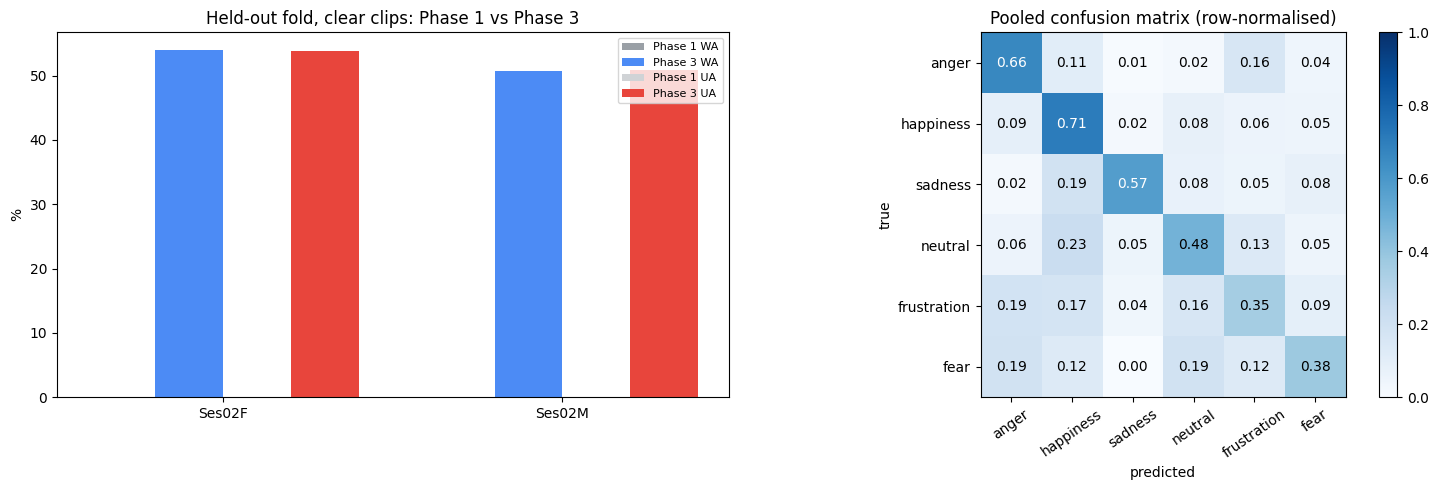

In [15]:
from scipy import stats
import matplotlib.pyplot as plt
R = load_all_results(); R = [R[k] for k in sorted(R)]
print(f"{len(R)} fold(s) finished: {[r['fold'] for r in R]}\n")
if any(r.get("leaky_phase1") for r in R): print("!! WARNING: some folds used a LEAKY Phase 1 checkpoint (it saw the held-out data). Those numbers are NOT held-out accuracy.\n")

print(f"{'fold':8s}{'#SA':>6s} | {'Phase 1 WA':>10s}{'UA':>7s} | {'Phase 3 WA':>10s}{'UA':>7s} | {'SA+SB WA':>9s}{'UA':>7s}")
for r in R:
    p1 = r.get("phase1"); a = f"{p1['WA_SA']:.2f}" if p1 else "-"; b = f"{p1['UA_SA']:.2f}" if p1 else "-"
    print(f"{r['fold']:8s}{r['n_test_SA']:6d} | {a:>10s}{b:>7s} | {r['WA_SA']:10.2f}{r['UA_SA']:7.2f} | {r['WA_ALL']:9.2f}{r['UA_ALL']:7.2f}")

def mean_ci(vals):
    v = np.array([x for x in vals if not math.isnan(x)]); n = len(v)
    if n == 0: return float("nan"), float("nan"), float("nan"), float("nan"), 0
    m = v.mean(); sd = v.std(ddof=1) if n > 1 else 0.0
    h = stats.t.ppf(0.975, n - 1) * sd / math.sqrt(n) if n > 1 else float("nan")
    return m, sd, m - h, m + h, n
print("\nMean +- std across folds  [95% CI, t-distribution]")
for key, name in [("WA_SA", "Phase 3  WA (clear test clips)"), ("UA_SA", "Phase 3  UA (clear test clips)"), ("WA_ALL", "Phase 3  WA (SA+SB)             "), ("UA_ALL", "Phase 3  UA (SA+SB)             ")]:
    m, sd, lo, hi, n = mean_ci([r[key] for r in R]); print(f"  {name}: {m:6.2f} +- {sd:5.2f}   [{lo:.2f}, {hi:.2f}]   (n={n} folds)")
p1s = [r["phase1"] for r in R if r.get("phase1")]
if p1s:
    for key, name in [("WA_SA", "Phase 1  WA (clear test clips)"), ("UA_SA", "Phase 1  UA (clear test clips)")]:
        m, sd, lo, hi, n = mean_ci([x[key] for x in p1s]); print(f"  {name}: {m:6.2f} +- {sd:5.2f}   [{lo:.2f}, {hi:.2f}]   (n={n} folds)")

cm = np.sum([np.array(r["cm_SA"]) for r in R], axis=0)
print("\nPooled confusion matrix over finished folds (clear test clips, rows = true):")
print(" " * 12 + "".join(f"{c[:8]:>10s}" for c in CLASS_NAMES) + f"{'recall':>9s}{'precision':>11s}")
for i, row in enumerate(cm):
    sup = row.sum(); rec = row[i] / sup if sup else float("nan"); col = cm[:, i].sum(); prec = row[i] / col if col else float("nan")
    print(f"{CLASS_NAMES[i]:12s}" + "".join(f"{v:10d}" for v in row) + f"{rec*100:8.1f}%{prec*100:10.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(R)); w = 0.2
ax[0].bar(x - 1.5*w, [r["phase1"]["WA_SA"] if r.get("phase1") else 0 for r in R], w, label="Phase 1 WA", color="#9aa0a6")
ax[0].bar(x - 0.5*w, [r["WA_SA"] for r in R], w, label="Phase 3 WA", color="#4c8bf5")
ax[0].bar(x + 0.5*w, [r["phase1"]["UA_SA"] if r.get("phase1") else 0 for r in R], w, label="Phase 1 UA", color="#d0d3d6")
ax[0].bar(x + 1.5*w, [r["UA_SA"] for r in R], w, label="Phase 3 UA", color="#e8453c")
ax[0].set_xticks(x); ax[0].set_xticklabels([r["fold"] for r in R]); ax[0].set_ylabel("%"); ax[0].set_title("Held-out fold, clear clips: Phase 1 vs Phase 3"); ax[0].legend(fontsize=8)
norm = cm / np.maximum(cm.sum(1, keepdims=True), 1); im = ax[1].imshow(norm, vmin=0, vmax=1, cmap="Blues"); ax[1].grid(False)
ax[1].set_xticks(range(NUM_CLASSES)); ax[1].set_xticklabels(CLASS_NAMES, rotation=35); ax[1].set_yticks(range(NUM_CLASSES)); ax[1].set_yticklabels(CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): ax[1].text(j, i, f"{norm[i,j]:.2f}", ha="center", va="center", color="white" if norm[i, j] > .5 else "black")
ax[1].set_title("Pooled confusion matrix (row-normalised)"); ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true"); fig.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, "summary.png"), dpi=150); plt.show()
